# Upper-air temperature trends over Central Europe with CUON

**Last updated:** 2026-10-13

**Raw vs. homogenised radiosonde temperatures, 1970–1990**

This notebook shows how to download radiosonde observations from the *Comprehensive Upper-air Observation Network* (CUON) on the Copernicus Climate Data Store (CDS), read the point-based CDM-Obs-Core NetCDF files with Xarray and Pandas, and compare regional temperature trends **with and without** the homogenisation adjustments that come with the dataset.

## The Comprehensive Upper-air Observation Network (CUON)

CUON is a global collection of balloon-borne upper-air observations (radiosondes and pilot balloons) from 1901 to the present. It merges several archives: NOAA's IGRA v2, NCAR's UADB, and the observation feedback of the ERA5 reanalysis. It covers more than 14,000 stations and reports up to about 35 km altitude.

Each observation comes with additional information:

* **`homogenisation_adjustment`**: a suggested bias correction. Radiosonde records contain artificial jumps from instrument changes, changes in radiation correction and changes in launch practice. These jumps can mask or fake climate trends. The adjustments are estimated mainly from time series of departures from the ERA5 background, and they are defined so that **adjusted = observation − adjustment**.
* **`uncertainty_value1`**: an estimate of the random uncertainty (1σ).
* **`fg_depar@body` / `an_depar@body`**: departures from the ERA5 first guess and analysis.

The data are delivered as a flat table in the [CDM-Obs-Core](https://github.com/glamod/common_data_model) format, with **one row per observation** (station, time, pressure level, value).

Dataset page: <https://cds.climate.copernicus.eu/datasets/insitu-comprehensive-upper-air-observation-network>

## Learning objectives

By the end of this notebook you will be able to:

* set up a CDS API request for CUON and download a regional subset year by year;
* read the CDM-Obs-Core NetCDF files and reshape them into station/level time series;
* apply the homogenisation adjustments;
* build regional temperature anomaly series and compare linear trends of raw and adjusted data at several pressure levels.

**Target audience:** beginner to intermediate users with basic Python knowledge (Pandas/Xarray, Matplotlib).

## Prepare your environment

You need a free [CDS account](https://cds.climate.copernicus.eu/how-to-api) and you must accept the CC-BY licence on the dataset's *Download* tab. Your API key goes in `~/.cdsapirc`.

The notebook uses `cdsapi`, `xarray`, `netCDF4`, `pandas`, `numpy`, `scipy`, `matplotlib` and `cartopy`. If a package is missing, install it with `pip install <package>`.


### Install and import packages

In [1]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### (Optional) Set your CDS credentials

If you already have a `~/.cdsapirc` file, leave `KEY = None`. Otherwise paste your personal access token here.

In [2]:
URL = "https://cds.climate.copernicus.eu/api"
KEY = None  # e.g. "abcd1234-...."; leave None to use ~/.cdsapirc

client = cdsapi.Client(url=URL, key=KEY) if KEY else cdsapi.Client()

2026-10-13 10:02:42,001 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


### Define the data request

We request **air temperature** for a box over Central Europe (46–52°N, 8–18°E), which covers southern Germany, Austria, Czechia and parts of Poland, Switzerland and northern Italy. The years are **1970–1990**.

The request runs **one year at a time**. This keeps each request small, about 8 MB and 1–2 minutes in the CDS queue. Files that already exist are skipped, so you can re-run the cell safely.

> The `area` keyword follows the CDS convention `[North, West, South, East]`.

In [3]:
DATASET = "insitu-comprehensive-upper-air-observation-network"
AREA = [52, 8, 46, 18]  # N, W, S, E
YEARS = range(1970, 1991)  # 1970 ... 1990
DATA_DIR = Path("cuon_data")
DATA_DIR.mkdir(exist_ok=True)


def request_for(year):
    return {
        "variable": ["air_temperature"],
        "year": [str(year)],
        "month": [f"{m:02d}" for m in range(1, 13)],
        "day": [f"{d:02d}" for d in range(1, 32)],
        "area": AREA,
        "data_format": "netcdf",
        "version": "1_1_0",
    }


files = []
for year in YEARS:
    target = DATA_DIR / f"cuon_air_temperature_{year}.nc"
    if not target.exists():
        print(f"Downloading {year} ...")
        client.retrieve(DATASET, request_for(year), str(target))
    files.append(target)

print(f"{len(files)} files ready in {DATA_DIR}/")

21 files ready in cuon_data/


## Read and inspect the data

Let's open one file to look at its structure. There is a single dimension, `index`: each entry is one observation. Station, time and pressure level are stored as *columns*, not as dimensions.

In [4]:
ds = xr.open_dataset(files[10])
ds

<xarray.Dataset> Size: 88MB
Dimensions:                                   (index: 300793)
Dimensions without coordinates: index
Data variables: (12/34)
    observation_id                            (index) |S20 6MB ...
    report_id                                 (index) |S20 6MB ...
    data_policy_licence                       (index) int32 1MB ...
    z_coordinate                              (index) float32 1MB ...
    z_coordinate_type                         (index) int32 1MB ...
    observation_height_above_station_surface  (index) float32 1MB ...
    ...                                        ...
    uncertainty_units1                        (index) |S5 2MB ...
    uncertainty_value1                        (index) float32 1MB ...
    longitude                                 (index) float32 1MB ...
    latitude                                  (index) float32 1MB ...
    longitude|header_table                    (index) float32 1MB ...
    latitude|header_table                     (index) float32 1MB ...
Attributes:
    featureType:               point
    contactemail:              https://support.ecmwf.int
    licence_list:              20180314_Copernicus_License_V1.1
    responsible_organisation:  ECMWF

In [5]:
for var in [
    "observation_value",
    "z_coordinate",
    "homogenisation_adjustment",
    "uncertainty_value1",
    "report_timestamp",
    "primary_station_id",
]:
    print(f"{var:28s}", ds[var].dtype, dict(ds[var].attrs))

observation_value            float32 {}
z_coordinate                 float32 {}
homogenisation_adjustment    float32 {}
uncertainty_value1           float32 {'long_name': 'random_uncertainty'}
report_timestamp             datetime64[ns] {'standard_name': 'time'}
primary_station_id           |S26 {}


Important columns for this notebook:

| column | meaning |
|---|---|
| `primary_station_id` | WIGOS station identifier, e.g. `0-20000-0-11035`. The last 5 digits are the WMO station number |
| `station_name` | station name |
| `report_timestamp` | launch time (UTC) |
| `z_coordinate` | pressure in **Pa** (`z_coordinate_type == 1`) |
| `observation_value` | temperature in **K** (raw) |
| `homogenisation_adjustment` | bias estimate in K; **adjusted = observation − adjustment** |

We now load all years. We keep only the main **standard pressure levels** and the columns we need, so memory use stays small.

In [6]:
LEVELS_HPA = [850, 700, 500, 300, 200, 100, 50]
COLUMNS = [
    "primary_station_id",
    "station_name",
    "report_timestamp",
    "z_coordinate",
    "observation_value",
    "homogenisation_adjustment",
    "latitude|header_table",
    "longitude|header_table",
]


def load_year(path):
    with xr.open_dataset(path) as ds:
        df = ds[COLUMNS].to_dataframe().reset_index(drop=True)
    df = df[df["z_coordinate"].isin(np.array(LEVELS_HPA) * 100.0)]
    for col in ["primary_station_id", "station_name"]:
        df[col] = df[col].str.decode("utf-8")
    return df

In [7]:
obs = pd.concat([load_year(f) for f in files], ignore_index=True)
obs = obs.rename(
    columns={
        "latitude|header_table": "lat",
        "longitude|header_table": "lon",
        "report_timestamp": "time",
    }
)
obs["plev"] = (obs["z_coordinate"] / 100).astype(int)

# Some stations appear under several WIGOS IDs (e.g. ...-0-10771 and ...-1-10771).
# The WMO block/station number (last 5 digits) identifies them uniquely.
obs["wmo"] = obs["primary_station_id"].str[-5:]

print(f"{len(obs):,} observations on standard levels, {obs['wmo'].nunique()} stations")
obs.head()

1,246,552 observations on standard levels, 56 stations


,primary_station_id,station_name,time,z_coordinate,observation_value,homogenisation_adjustment,lat,lon,plev,wmo
0,0-20000-0-10771,KUEMMERSBRUCK (10771-0),1970-01-01 05:30:00,5000.0,210.500000,-0.178800,49.43,11.9,50,10771
1,0-20000-0-10771,KUEMMERSBRUCK (10771-0),1970-01-01 05:30:00,10000.0,215.600006,-0.233582,49.43,11.9,100,10771
2,0-20000-0-10771,KUEMMERSBRUCK (10771-0),1970-01-01 05:30:00,20000.0,216.699997,-0.048058,49.43,11.9,200,10771
3,0-20000-0-10771,KUEMMERSBRUCK (10771-0),1970-01-01 05:30:00,30000.0,218.199997,0.576350,49.43,11.9,300,10771
4,0-20000-0-10771,KUEMMERSBRUCK (10771-0),1970-01-01 05:30:00,50000.0,244.300003,0.292008,49.43,11.9,500,10771


## Explore stations and adjustments

### Where are the stations?

Many stations report only occasionally. For trend analysis we need long and fairly complete records, so we count the months with data at 500 hPa for each station.

In [8]:
stations = (
    obs[obs["plev"] == 500]
    .assign(month=lambda d: d["time"].dt.to_period("M"))
    .groupby("wmo")
    .agg(
        name=("station_name", "last"),
        lat=("lat", "median"),
        lon=("lon", "median"),
        n_months=("month", "nunique"),
    )
    .sort_values("n_months", ascending=False)
)
stations.head(15)

,name,lat,lon,n_months
wmo,,,,
10548,MEININGEN (10548-1),50.561668,10.376945,252
10488,DRESDEN-KLOTZSCHE,51.119999,13.680000,252
11520,PRAHA-LIBUS,50.000000,14.450000,252
11035,WIEN/HOHE WARTE (11035-1),48.250000,16.370001,252
10868,MUENCHEN-OBERSCHLEISSHEIM,48.250000,11.550000,252
10954,ALTENSTADT,47.834167,10.866667,252
10771,KUEMMERSBRUCK (10771-1),49.428333,11.901667,252
10739,STUTTGART/SCHNARRENBERG (10739,48.830002,9.200000,252
12425,WROCLAW-STARACHOWICE,51.130001,16.980000,252


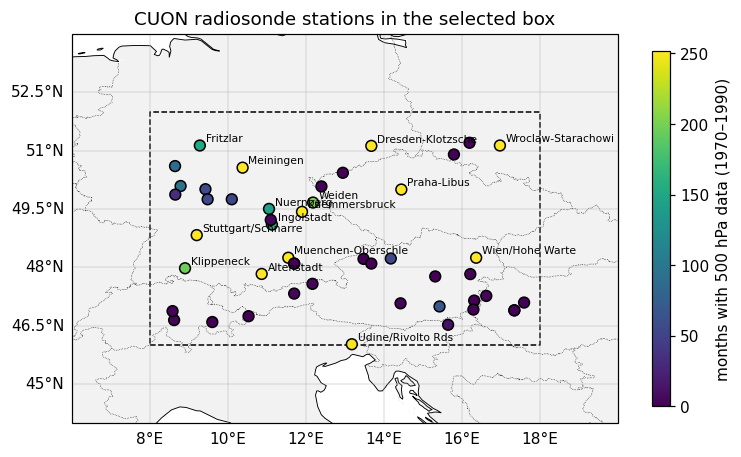

In [9]:
pc = ccrs.PlateCarree()
box_lon = [AREA[1], AREA[3], AREA[3], AREA[1], AREA[1]]
box_lat = [AREA[2], AREA[2], AREA[0], AREA[0], AREA[2]]
style = {
    "s": 50,
    "cmap": "viridis",
    "edgecolor": "k",
    "vmin": 0,
    "vmax": 12 * len(YEARS),
    "zorder": 3,
}

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=pc)
ax.set_extent([AREA[1] - 2, AREA[3] + 2, AREA[2] - 2, AREA[0] + 2])
ax.add_feature(cfeature.LAND, facecolor="0.95")
ax.coastlines(resolution="50m", linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=":")
ax.plot(box_lon, box_lat, "k--", lw=1, transform=pc)
sc = ax.scatter(
    stations["lon"], stations["lat"], c=stations["n_months"], transform=pc, **style
)
for wmo, row in stations[stations["n_months"] > 100].iterrows():
    name = row["name"].split("(")[0].title()[:18]
    ax.text(row["lon"] + 0.15, row["lat"] + 0.1, name, fontsize=7, transform=pc)
gl = ax.gridlines(draw_labels=True, linewidth=0.3)
gl.top_labels = gl.right_labels = False
plt.colorbar(sc, ax=ax, shrink=0.7, label="months with 500 hPa data (1970–1990)")
ax.set_title("CUON radiosonde stations in the selected box")
plt.show()

**Figure 1.** CUON radiosonde stations in the selected box (dashed line), coloured by the number of months with 500 hPa data in 1970–1990.

*Source: Comprehensive Upper-air Observation Network (CUON), Copernicus Climate Change Service, Climate Data Store, DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a).*

### What do the adjustments look like?

Before averaging, we add the **adjusted temperature**. We also keep only observations where an adjustment is available. Then the raw and adjusted series use **exactly the same sample**, and any difference in trend comes from the adjustment alone.

We also keep only the two main synoptic launch times (nominal 00 and 12 UTC). Without this filter, a change in the number of launches per day could itself cause a jump. Launches are often made about an hour before the nominal time, so we round to the nearest 12 h.

In [10]:
obs["adjusted"] = obs["observation_value"] - obs["homogenisation_adjustment"]

# 21-02 UTC -> 0, 09-14 UTC -> 12
nominal_hour = (obs["time"] + pd.Timedelta(hours=3)).dt.hour // 6 * 6
sel = obs[obs["homogenisation_adjustment"].notna() & nominal_hour.isin([0, 12])].copy()
sel["month"] = sel["time"].dt.to_period("M").dt.to_timestamp()

print(
    f"Adjustment available for {obs['homogenisation_adjustment'].notna().mean():.0%} of observations"
)
print(f"{len(sel):,} observations kept (00/12 UTC, with adjustment)")

Adjustment available for 95% of observations
840,522 observations kept (00/12 UTC, with adjustment)


We compute **monthly means** per station and level, and require at least 10 ascents per month.

In [11]:
monthly = (
    sel.groupby(["wmo", "plev", "month"])
    .agg(
        raw=("observation_value", "mean"),
        adjusted=("adjusted", "mean"),
        adjustment=("homogenisation_adjustment", "mean"),
        n=("observation_value", "size"),
    )
    .query("n >= 10")
)
monthly.head()

raw    adjusted  adjustment   n
wmo   plev month                                             
06750 50   1982-03-01  218.636597  218.636597         0.0  35
           1982-04-01  216.865326  216.865326         0.0  40
      100  1982-03-01  219.963867  219.963867         0.0  40
           1982-04-01  218.187912  218.187912         0.0  42
      200  1982-03-01  219.317856  219.317856         0.0  41

Let's look at one long record, Wien/Hohe Warte (WMO 11035), at 300 hPa. The bottom panel shows the applied adjustment. Its step changes mark the breakpoints that the homogenisation detected, for example a change of radiosonde type.

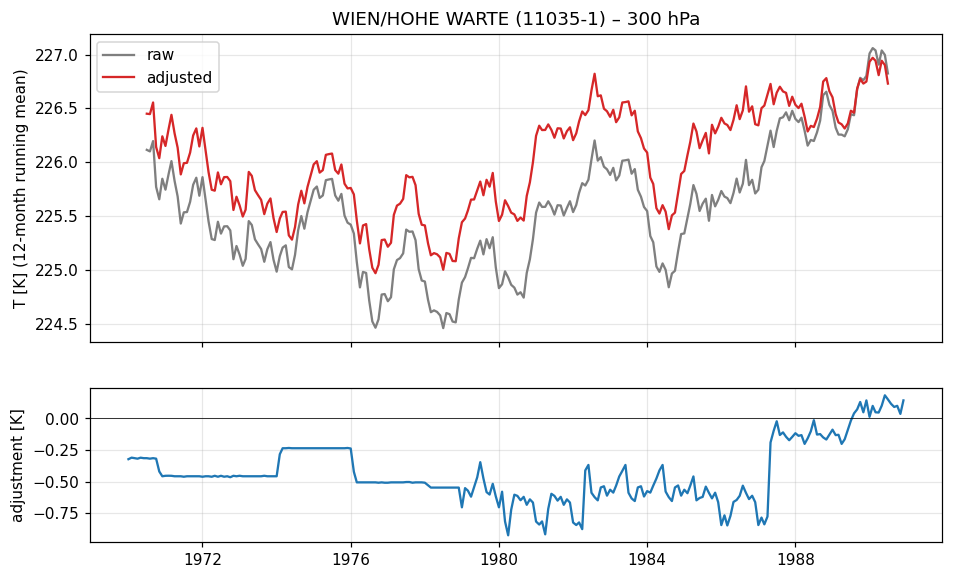

In [12]:
STATION, LEVEL = "11035", 300

ts = monthly.loc[(STATION, LEVEL)]
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
ax1.plot(
    ts.index, ts["raw"].rolling(12, center=True).mean(), color="tab:gray", label="raw"
)
ax1.plot(
    ts.index,
    ts["adjusted"].rolling(12, center=True).mean(),
    color="tab:red",
    label="adjusted",
)
ax1.set_ylabel("T [K] (12-month running mean)")
ax1.legend()
ax1.set_title(f"{stations.loc[STATION, 'name']} – {LEVEL} hPa")
ax2.plot(ts.index, ts["adjustment"], color="tab:blue")
ax2.axhline(0, color="k", lw=0.5)
ax2.set_ylabel("adjustment [K]")
plt.show()

**Figure 2.** Wien/Hohe Warte (WMO 11035) at 300 hPa. Top: 12-month running mean of raw and adjusted temperature. Bottom: monthly mean homogenisation adjustment.

*Source: Comprehensive Upper-air Observation Network (CUON), Copernicus Climate Change Service, Climate Data Store, DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a).*

## Regional temperature trends, with and without adjustments

### Station anomalies and regional mean

For each station and level we:

1. require a fairly complete record: at least 70% of all months between 1970 and 1990;
2. subtract the station's own mean annual cycle (calendar-month climatology over 1970–1990), separately for the raw and the adjusted series;
3. average the anomalies over all stations to get a **regional anomaly series**.

In [13]:
MIN_COVERAGE = 0.7
n_months_total = 12 * len(YEARS)


def anomalies(df):
    clim = df.groupby(df.index.get_level_values("month").month).transform("mean")
    return df - clim


cover = monthly.groupby(["wmo", "plev"]).size() / n_months_total
good = cover[cover >= MIN_COVERAGE].index
mon_good = monthly.loc[monthly.index.droplevel("month").isin(good), ["raw", "adjusted"]]

anom = mon_good.groupby(["wmo", "plev"], group_keys=False).apply(anomalies)
regional = anom.groupby(["plev", "month"]).mean()

print("Stations used per level:")
print(
    pd.Series(good.get_level_values("plev"))
    .value_counts()
    .sort_index(ascending=False)
    .to_string()
)

Stations used per level:
plev
850    9
700    9
500    9
300    9
200    9
100    8
50     7


### Linear trends

We fit an ordinary least-squares trend to the monthly regional anomalies and express it in **K per decade**. The ± values are 2× the standard error of the slope. They do **not** account for autocorrelation, so the real uncertainty is larger.

In [14]:
def trend_per_decade(series):
    s = series.dropna()
    t = s.index.year + (s.index.month - 0.5) / 12
    res = stats.linregress(t, s.values)
    return 10 * res.slope, 20 * res.stderr


rows = []
for plev in LEVELS_HPA:
    if plev not in regional.index.get_level_values("plev"):
        continue
    r = regional.loc[plev]
    for kind in ["raw", "adjusted"]:
        slope, err = trend_per_decade(r[kind])
        rows.append({"plev": plev, "data": kind, "trend": slope, "2se": err})

trends = pd.DataFrame(rows).pivot(index="plev", columns="data", values=["trend", "2se"])
trends = trends.sort_index(ascending=False).round(3)
trends

trend             2se       
data adjusted    raw adjusted    raw
plev                                
850     0.404  0.480    0.381  0.381
700     0.511  0.558    0.365  0.365
500     0.574  0.569    0.331  0.331
300     0.446  0.424    0.218  0.223
200    -0.348 -0.400    0.383  0.384
100    -0.246 -0.356    0.277  0.278
50     -0.315 -0.410    0.323  0.324

### Time series of the regional anomalies

The first plot compares the raw and adjusted regional mean in the upper troposphere (300 hPa) and the lower stratosphere (100 hPa). These are the layers where radiosonde biases (mostly solar radiation errors) are largest.

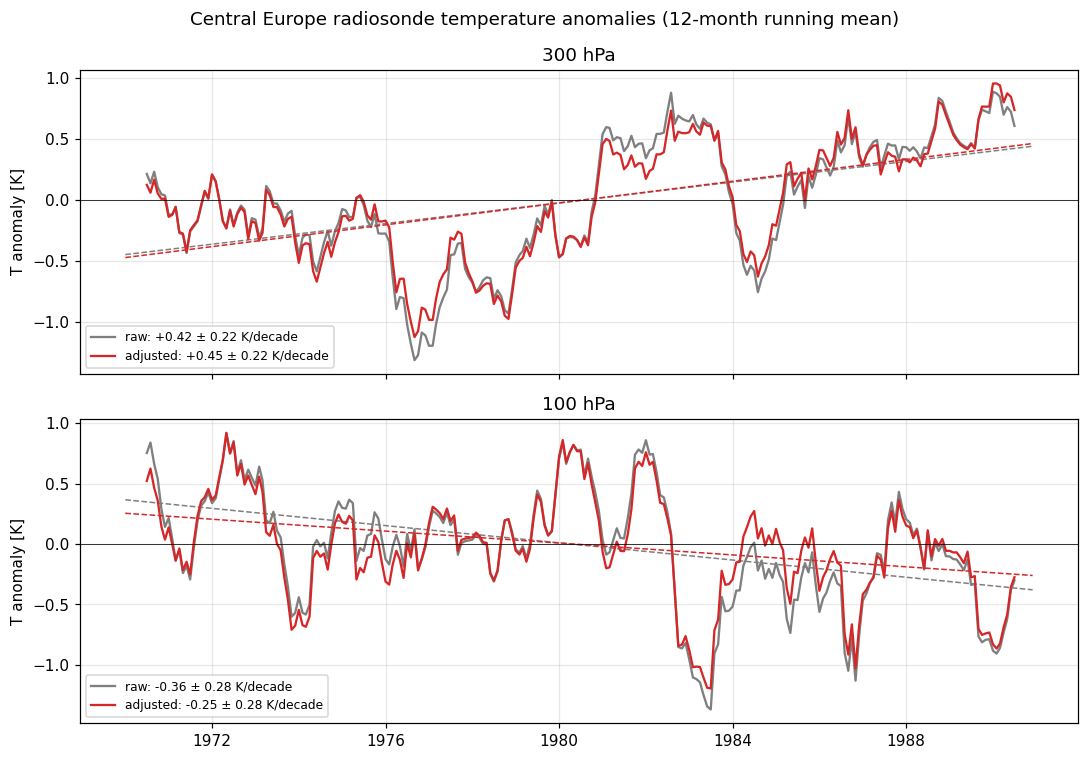

In [15]:
def plot_level(ax, plev):
    r = regional.loc[plev]
    for kind, color in [("raw", "tab:gray"), ("adjusted", "tab:red")]:
        s = r[kind]
        slope, err = trend_per_decade(s)
        ax.plot(
            s.index,
            s.rolling(12, center=True).mean(),
            color=color,
            label=f"{kind}: {slope:+.2f} ± {err:.2f} K/decade",
        )
        t = s.index.year + (s.index.month - 0.5) / 12
        fit = stats.linregress(t, s.values)
        ax.plot(s.index, fit.intercept + fit.slope * t, color=color, ls="--", lw=1)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"{plev} hPa")
    ax.set_ylabel("T anomaly [K]")
    ax.legend(loc="lower left", fontsize=8)


fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, plev in zip(axes, [300, 100]):
    plot_level(ax, plev)
fig.suptitle("Central Europe radiosonde temperature anomalies (12-month running mean)")
plt.tight_layout()
plt.show()

**Figure 3.** Regional mean temperature anomalies at 300 hPa and 100 hPa (12-month running mean) for raw and adjusted data, with linear trends (dashed).

*Source: Comprehensive Upper-air Observation Network (CUON), Copernicus Climate Change Service, Climate Data Store, DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a).*

### Vertical profile of the trends

The trend profile is a compact summary: how much the region warmed or cooled at each level between 1970 and 1990, with and without homogenisation.

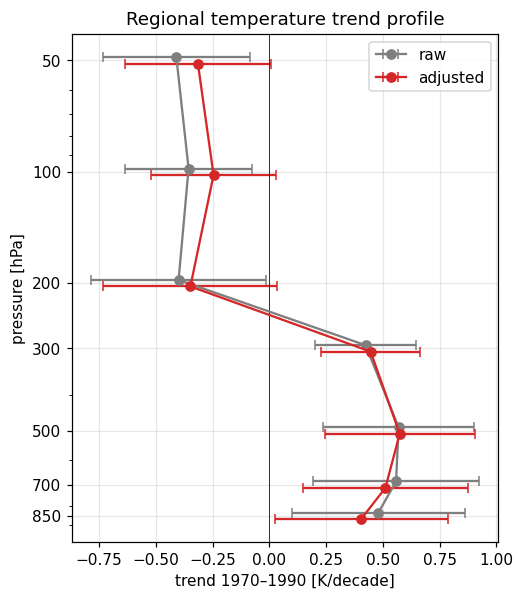

In [16]:
fig, ax = plt.subplots(figsize=(5, 6))
for kind, color, offset in [("raw", "tab:gray", -0.02), ("adjusted", "tab:red", 0.02)]:
    p = trends.index.values
    ax.errorbar(
        trends[("trend", kind)],
        p * (1 + offset),
        xerr=trends[("2se", kind)],
        fmt="o-",
        color=color,
        capsize=3,
        label=kind,
    )
ax.axvline(0, color="k", lw=0.5)
ax.set_yscale("log")
ax.set_yticks(LEVELS_HPA)
ax.set_yticklabels(LEVELS_HPA)
ax.invert_yaxis()
ax.set_xlabel("trend 1970–1990 [K/decade]")
ax.set_ylabel("pressure [hPa]")
ax.set_title("Regional temperature trend profile")
ax.legend()
plt.show()

**Figure 4.** Vertical profile of the 1970–1990 regional temperature trends for raw and adjusted data. Error bars show ±2 standard errors.

*Source: Comprehensive Upper-air Observation Network (CUON), Copernicus Climate Change Service, Climate Data Store, DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a).*

### Trends at individual stations

Homogenisation should also make stations **agree more** with each other. Neighbouring stations in a region of this size should have similar trends. Differences between them are often caused by instrument changes, not by real climate signals.

In [17]:
LEVEL = 300

rows = []
for wmo, s in anom.xs(LEVEL, level="plev").groupby(level="wmo"):
    s = s.droplevel("wmo")
    raw, _ = trend_per_decade(s["raw"])
    adj, _ = trend_per_decade(s["adjusted"])
    rows.append(
        {
            "station": stations.loc[wmo, "name"].split("(")[0].title(),
            "raw": raw,
            "adjusted": adj,
        }
    )
st_trends = pd.DataFrame(rows).set_index("station").sort_values("raw")

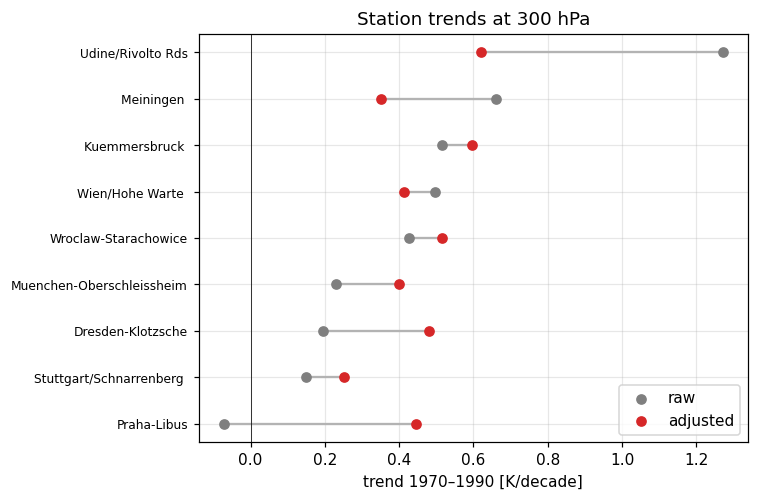

Spread (std) of station trends [K/decade]:
raw         0.387
adjusted    0.117


In [18]:
fig, ax = plt.subplots(figsize=(7, 0.35 * len(st_trends) + 1.5))
y = np.arange(len(st_trends))
ax.hlines(y, st_trends["raw"], st_trends["adjusted"], color="0.7")
ax.scatter(st_trends["raw"], y, color="tab:gray", label="raw", zorder=3)
ax.scatter(st_trends["adjusted"], y, color="tab:red", label="adjusted", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(st_trends.index, fontsize=8)
ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("trend 1970–1990 [K/decade]")
ax.set_title(f"Station trends at {LEVEL} hPa")
ax.legend()
plt.tight_layout()
plt.show()

print("Spread (std) of station trends [K/decade]:")
print(st_trends.std().round(3).to_string())

**Figure 5.** Trends 1970–1990 at 300 hPa for individual stations, raw (grey) and adjusted (red).

*Source: Comprehensive Upper-air Observation Network (CUON), Copernicus Climate Change Service, Climate Data Store, DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a).*

## Take-home messages

* CUON data are point observations in CDM-Obs-Core format, with one row per observation. Pivoting by station, pressure level (`z_coordinate`, in Pa) and time is the first step in most analyses.
* Every temperature value comes with a suggested **homogenisation adjustment**. The adjusted value is `observation_value - homogenisation_adjustment`.
* Comparing raw and adjusted data on **the same sample** isolates the effect of the bias correction on trends.
* Adjustments usually matter most in the upper troposphere and stratosphere, where radiation errors of the sondes are largest. They also reduce the spread of trends between neighbouring stations.
* Twenty years over a small region is a short, noisy record. Treat these trends as an illustration of the method, not as a climate assessment.

### Ideas to explore further

* Extend the period (e.g. 1958–2020) or enlarge the box.
* Compare 00 UTC and 12 UTC launches separately. Daytime launches are affected more by solar radiation errors.
* Use `fg_depar@body` to compare the stations with ERA5.
* Repeat the analysis for humidity (`relative_humidity`, `dew_point_depression`) or wind.

## References

* Copernicus Climate Change Service (2025): *Comprehensive Upper-air Observation Network from 1905 to present*. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). DOI: [10.24381/ba504f7a](https://doi.org/10.24381/ba504f7a)
* Haimberger, L., Tavolato, C. and Sperka, S. (2012): Homogenization of the global radiosonde temperature dataset through combined comparison with reanalysis background series and neighboring stations. *J. Climate*, 25, 8108–8131. DOI: 10.1175/JCLI-D-11-00668.1
* Product User Guide and ATBD: see the *Documentation* tab of the dataset page.